# EDA básico de QuickDraw

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from etl import cargar_datos, comprobar_sin_fugas, ruta_particiones
from quickdraw_config import CLASES_ES, leer_json

# Los mismos valores predeterminados que el entrenamiento.
POR_CLASE = 5000
SEMILLA = 42
PRUEBA_CORTA = False
RAIZ = Path.cwd()  # Ejecutar desde la raíz del repo.


## Carga mediante ETL

La limpieza descarta imágenes vacías, deduplica globalmente y excluye patrones con etiquetas contradictorias antes de muestrear. Las particiones se guardan como uint8 sin normalizar; normalización y aumento permanecen dentro del modelo.

In [2]:
por_clase = 100 if PRUEBA_CORTA else POR_CLASE
datos, firma = cargar_datos(por_clase, SEMILLA, PRUEBA_CORTA, raiz=RAIZ)
manifiesto = leer_json(ruta_particiones(por_clase, SEMILLA, PRUEBA_CORTA, RAIZ) / 'manifiesto.json')
print('Firma del manifiesto:', firma)
comprobar_sin_fugas(datos)
print('Sin imágenes idénticas dentro de ni entre las particiones.')


train (35000, 28, 28, 1)
val (7500, 28, 28, 1)
test (7500, 28, 28, 1)
Firma del manifiesto: f2a4ae21a0d04742f4f1713aecd4ee029270ce96e5801e6a98158a1d176483fd
Sin imágenes idénticas dentro de ni entre las particiones.


## Calidad de las fuentes

Estos conteos corresponden a todas las fuentes originales examinadas, antes del muestreo. “Repeticiones” cuenta apariciones adicionales; “patrones contradictorios” cuenta patrones únicos presentes con distintas etiquetas. No son cantidades que se deban sumar como descartes independientes.

In [3]:
limpieza = manifiesto['limpieza']
print('Imágenes vacías:', limpieza['vacias'])
print('Apariciones repetidas:', limpieza['repeticiones'])
print('Patrones con etiquetas contradictorias:', limpieza['patrones_con_etiquetas_contradictorias'])
print('Candidatos válidos por clase:')
for clase, cantidad in zip(CLASES_ES, limpieza['candidatos_por_clase']):
    print(f'  {clase}: {cantidad}')


Imágenes vacías: 0
Apariciones repetidas: 38
Patrones con etiquetas contradictorias: 10
Candidatos válidos por clase:
  gato: 123192
  pez: 134148
  bicicleta: 126527
  avión: 151609
  casa: 135417
  árbol: 144716
  reloj: 120536
  paraguas: 124077
  helado: 123131
  estrella: 137614


## Balance por clase y partición

Se consultan las etiquetas de entrenamiento, validación y test para contar muestras. La división es 70/15/15 por clase, con redondeo entero y el remanente asignado a test.

Clase             Train      Val     Test
gato               3500      750      750
pez                3500      750      750
bicicleta          3500      750      750
avión              3500      750      750
casa               3500      750      750
árbol              3500      750      750
reloj              3500      750      750
paraguas           3500      750      750
helado             3500      750      750
estrella           3500      750      750
train: 35000 imágenes
val: 7500 imágenes
test: 7500 imágenes


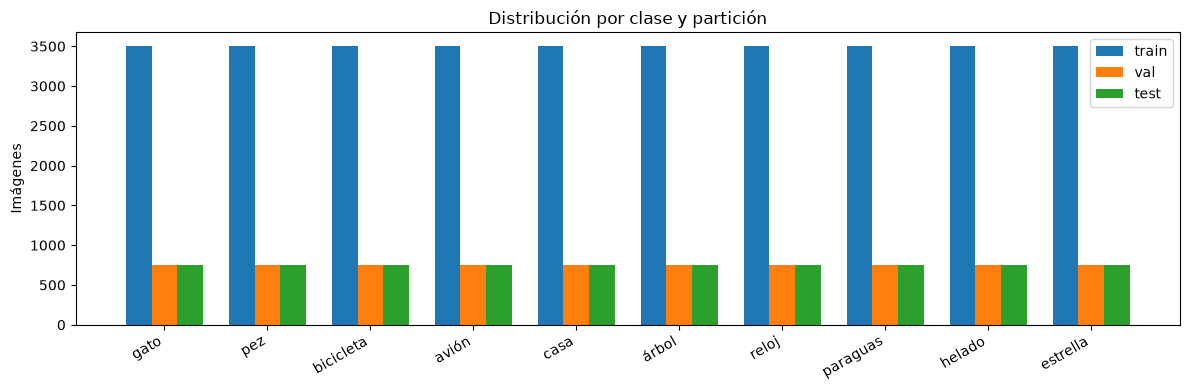

In [4]:
partes = ('train', 'val', 'test')
conteos = {parte: np.bincount(datos['y_' + parte], minlength=len(CLASES_ES))
           for parte in partes}
print(f"{'Clase':<14} {'Train':>8} {'Val':>8} {'Test':>8}")
for i, clase in enumerate(CLASES_ES):
    print(f"{clase:<14} {conteos['train'][i]:>8} {conteos['val'][i]:>8} {conteos['test'][i]:>8}")
for parte in partes:
    print(f'{parte}: {conteos[parte].sum()} imágenes')

fig, ax = plt.subplots(figsize=(12, 4))
posiciones = np.arange(len(CLASES_ES))
for desplazamiento, parte in enumerate(partes):
    ax.bar(posiciones + (desplazamiento - 1) * .25, conteos[parte], width=.25, label=parte)
ax.set_xticks(posiciones, CLASES_ES, rotation=30, ha='right')
ax.set_ylabel('Imágenes')
ax.set_title('Distribución por clase y partición')
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)


## Formato e intensidades de entrenamiento

Las estadísticas de píxeles y los ejemplos usan exclusivamente entrenamiento. Validación y test se reservan para la evaluación posterior de los modelos.

Forma de entrenamiento: (35000, 28, 28, 1)
Tipo: uint8
Rango observado: 0 a 255
Rango esperado del formato: 0 a 255
Media de intensidad: 42.35093505830904
Fracción de píxeles con intensidad distinta de cero: 0.28105885568513117


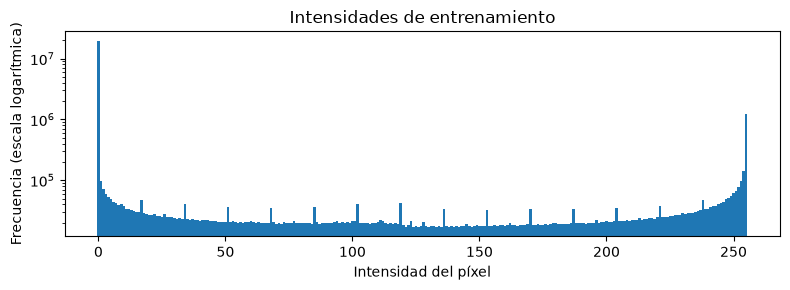

In [5]:
x_train = datos['x_train']
print('Forma de entrenamiento:', x_train.shape)
print('Tipo:', x_train.dtype)
print('Rango observado:', int(x_train.min()), 'a', int(x_train.max()))
print('Rango esperado del formato: 0 a 255')
print('Media de intensidad:', float(x_train.mean()))
print('Fracción de píxeles con intensidad distinta de cero:',
      float(np.count_nonzero(x_train) / x_train.size))

fig, ax = plt.subplots(figsize=(8, 3))
frecuencias = np.bincount(x_train.ravel(), minlength=256)
ax.bar(np.arange(256), frecuencias, width=1)
ax.set_yscale('log')
ax.set_xlabel('Intensidad del píxel')
ax.set_ylabel('Frecuencia (escala logarítmica)')
ax.set_title('Intensidades de entrenamiento')
fig.tight_layout()
display(fig)
plt.close(fig)


## Ejemplos reproducibles por clase

Tres ejemplos de entrenamiento por categoría, elegidos con la semilla configurada. Se muestran con fondo negro y trazo claro, sin aumento de datos.

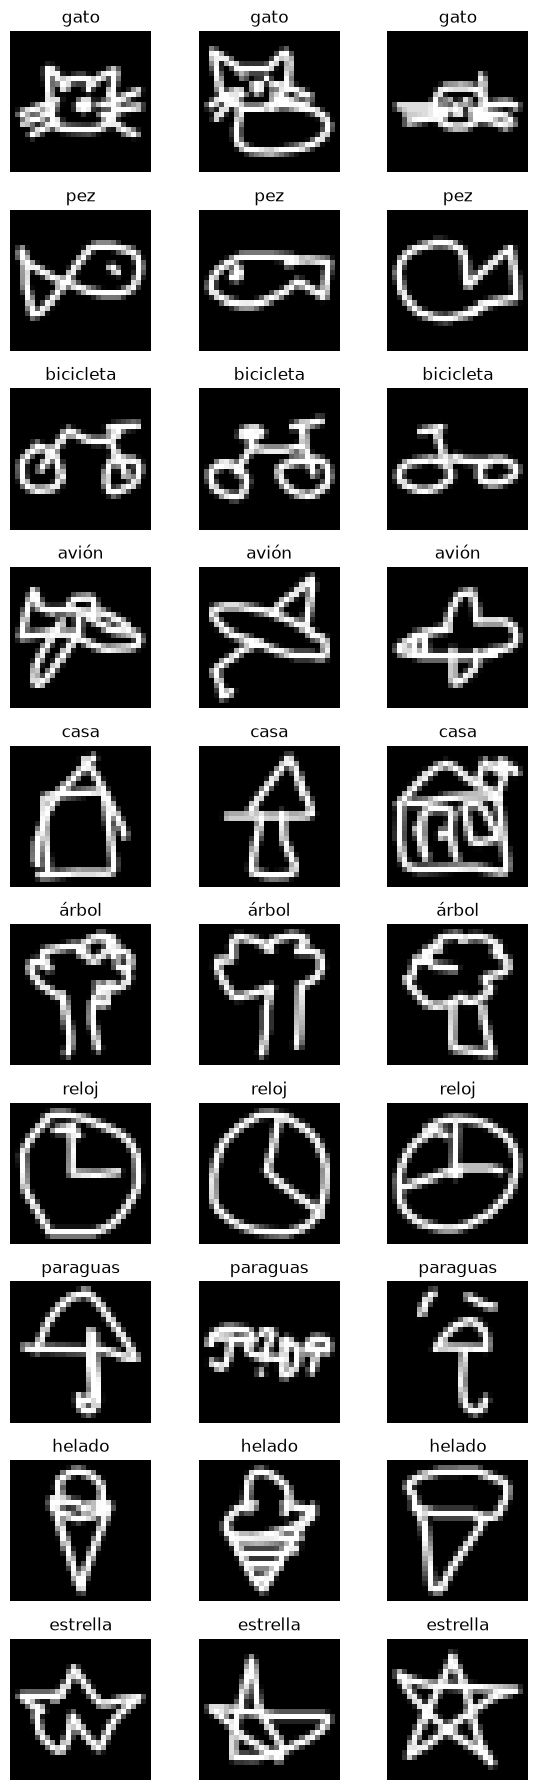

In [6]:
rng = np.random.default_rng(SEMILLA)
fig, ejes = plt.subplots(len(CLASES_ES), 3, figsize=(6, 18))
for clase, nombre in enumerate(CLASES_ES):
    candidatos = np.flatnonzero(datos['y_train'] == clase)
    elegidos = rng.choice(candidatos, size=3, replace=False)
    for columna, indice in enumerate(elegidos):
        eje = ejes[clase, columna]
        eje.imshow(x_train[indice, ..., 0], cmap='gray', vmin=0, vmax=255)
        eje.set_title(nombre)
        eje.axis('off')
fig.tight_layout()
display(fig)
plt.close(fig)
